# Продажи автомобилей в Казахстане и позиция «Меркур Авто»

**Максим Лапин · Январь–сентябрь 2019 года**

Цель — подготовить данные для дальнейшего анализа и оценить позиции «Меркур Авто» на внутреннем рынке. Здесь показаны правила оценки, расчёты, срезы и проверка устойчивости результатов. Пояснения для менеджмента — в [отчёте](report.md).

Для запуска нужны pandas, NumPy и Matplotlib. Поместите ноутбук и [скрипт очистки](clean_autokz.py) в одну папку. Скрипт читает autokz2019.csv из рабочей папки или официальную копию из задания.

## 1. Исходная выгрузка и результат очистки

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from clean_autokz import DROPPED, MERCUR, SOURCE_URL, clean_sales, normalize_key, read_sales

local_file = Path('autokz2019.csv')
raw = read_sales(local_file if local_file.is_file() else SOURCE_URL)
display(raw.head(3))
display(pd.DataFrame({
    'Тип исходных данных': raw.dtypes, 'Пропусков': raw.isna().sum(),
    'Доля пропусков, %': (raw.isna().mean() * 100).round(2),
}))

,Год,Месяц,Компания,Бренд,Модель,Модификация,Год выпуска,Страна-производитель,Вид топлива,"Объём двиг, л,",...,Тип клиента,Форма расчета,Количество,"Цена, USD","Продажа, USD",Область,Сегментация 2013,Класс 2013,Сегментация Eng,Локализация производства
0,2019,Май,Mercur Auto,Audi,A3,TFSI,2018,Германия,Бензин,"1,4",...,Физ. Лицо,безналичный,1.0,28115.00,28115.00,г.Алматы,Легковые автомобили,C класс,C,Импорт
1,2019,Август,Mercur Auto,Audi,A3,TFSI,2018,Германия,Бензин,"1,4",...,Юр. Лицо,наличный,1.0,32246.99,32246.99,г.Алматы,Легковые автомобили,C класс,C,Импорт
2,2019,Апрель,Mercur Auto,Audi,A4,TFSI,2018,Германия,Бензин,"1,4",...,Физ. Лицо,безналичный,1.0,32000.00,32000.00,г.Алматы,Легковые автомобили,D класс,D,Импорт


,Тип исходных данных,Пропусков,"Доля пропусков, %"
Год,int64,0,0.00
Месяц,str,0,0.00
Компания,str,0,0.00
Бренд,str,0,0.00
Модель,str,0,0.00
Модификация,str,3591,8.99
Год выпуска,str,501,1.25
Страна-производитель,str,0,0.00
Вид топлива,str,3140,7.86
"Объём двиг, л,",str,4258,10.65


In [2]:
sales, audit = clean_sales(raw)
display(pd.Series(audit, name='Количество').to_frame())
display(pd.DataFrame({
    'Тип после очистки': sales.dtypes, 'Пропусков': sales.isna().sum(),
    'Уникальных значений': sales.nunique(),
}))
display(sales.head(3))

source_distinct = raw.dropna(how='all').drop_duplicates().reset_index(drop=True)
text_columns = source_distinct.select_dtypes(include=['object', 'string']).columns
source_normalized = source_distinct.assign(**{
    column: normalize_key(source_distinct[column]) for column in text_columns
})
dimensions = [column for column in DROPPED if column in source_normalized.columns]
comparison = pd.concat([sales, source_normalized[dimensions]], axis=1)
display(pd.Series({
    'Совпадения после нормализации пробелов и регистра в исходных полях':
        source_normalized.duplicated().sum(),
    'Совпадения после всех преобразований при сохранённых исходных измерениях':
        comparison.duplicated().sum(),
    'Совпадения по полям итогового CSV': sales.duplicated().sum(),
}, name='Количество').to_frame())

,Количество
Исходных строк,39966
Полностью пустых строк,0
Удалено точных повторов,18698
В итоговой таблице строк,21268
Строк Renault с исправленным сдвигом полей,27
Исправлено объёмов Chevrolet Niva,25
Исправлено объёмов Volkswagen Polo,1
Исправлено объёмов Isuzu NMR85,1
Jaguar I-Pace без объёма ДВС,4
Электромобилей JAC iEV7S,1


,Тип после очистки,Пропусков,Уникальных значений
sale_date,datetime64[us],0,9
company,str,0,33
brand,string,0,46
model,string,0,273
model_year,Int64,233,7
country_code,string,0,19
fuel_type,category,1916,4
engine_l,float64,2299,56
transmission,category,1889,2
drive_type,category,2294,4


,sale_date,company,brand,model,model_year,country_code,fuel_type,engine_l,transmission,drive_type,region,quantity,unit_price_usd,sales_usd,oblast,segment_2013,class_2013
0,2019-05-31,Mercur Auto,Audi,A3,2018,DEU,F,1.4,Автомат,FWD,Алматы,1,28115.00,28115.00,Г. Алматы,Легковые автомобили,C класс
1,2019-08-31,Mercur Auto,Audi,A3,2018,DEU,F,1.4,Автомат,FWD,Алматы,1,32246.99,32246.99,Г. Алматы,Легковые автомобили,C класс
2,2019-04-30,Mercur Auto,Audi,A4,2018,DEU,F,1.4,Автомат,FWD,Алматы,1,32000.00,32000.00,Г. Алматы,Легковые автомобили,D класс


,Количество
Совпадения после нормализации пробелов и регистра в исходных полях,19
Совпадения после всех преобразований при сохранённых исходных измерениях,50
Совпадения по полям итогового CSV,4824


Сначала сравнили записи по всем исходным полям, затем удалили лишние столбцы. Из 39 966 записей 18 698 совпали целиком. После очистки осталось 21 268 записей. После нормализации пробелов и регистра по полной схеме обнаружили ещё 19 совпадений. Даже при сохранении удаляемых измерений комплексная очистка дала 50 совпадений. В итоговой сокращённой схеме после очистки совпадают 4 824 строки: например, бывший тип клиента или дилер могли различаться при одинаковых оставшихся полях. Эти счётчики описывают разные этапы и не складываются. Записи сохраняем, так как совпадение преобразованных полей не устанавливает факт повторной выгрузки. Без идентификатора операции даже полное исходное совпадение не доказывает повторную выгрузку. В конце сравним результаты с расчётом на исходной кратности записей.

- Привели страны к кодам ISO 3166-1 alpha-3, текстовые варианты привода и компании — к единым значениям. Сохранили 2WD отдельно от переднего и заднего приводов. В исходнике с дополнительной кодировкой есть поле «Сегментация Eng». Его исключили вместе с остальными вспомогательными столбцами. Сегментация и класс 2013 года используются для анализа.
- Преобразовали год выпуска, цены, количество и итоговую стоимость в числовые типы, а месяц продажи — в календарную дату конца месяца. Объём двигателя в литрах извлекли с учётом десятичной запятой и обозначений вроде L и MPI. Механические коробки относятся к «Механике», автоматические, роботизированные и вариаторы — к «Автомату». Редуктор электромобиля отнесён к немеханическому управлению передачами в рамках двух категорий.
- У 27 строк Renault восстановили объём и коробку там, где часть характеристик сдвинулась по столбцам. Топливо в этих строках оставили неизвестным. У 25 Chevrolet Niva восстановили 1,7 л по нормальным записям той же модели и спецификации производителя. Для Volkswagen Polo Comfortline MPI и Isuzu NMR85 исправили 8,7 л на 1,6 и 3,0 л соответственно. Точные модификации сверили с другими строками исходника и техническими характеристиками. У Jaguar I-Pace вместо объёма была указана мощность 400 л. с. Электромобилям оставили пустой объём ДВС, включая электробус ANKAI с ёмкостью аккумулятора в поле объёма. У JAC iEV7S в исходнике ошибочно указан бензин. По спецификации производителя это электромобиль, поэтому топливу присвоили код E. Модификации Porsche с явным обозначением E-Hybrid отнесли к гибридам.
- В шести строках с нулевой выручкой количество отсутствовало. Оставили пропуски. Сумма каждой операции с известным количеством совпадает с количеством, умноженным на цену за автомобиль, с точностью до цента. Отрицательное количество сохранено как возврат. Реальные крупные партии также сохранены.

[Коды стран ISO](https://www.iso.org/iso-3166-country-codes.html?content_language=English) · [Спецификация Chevrolet Niva](https://niva-ufa.ru/upload/iblock/ab1/ab11b7a7c19135b23393c9d75c5f21f6.pdf) · [Характеристики Jaguar I-Pace](https://media.jlr.com/archive-jaguar/en-gb/news/2018/03/jaguar-charges-ahead-new-all-electric-i-pace) · [Volkswagen Polo, Казахстан, модельный год 2019](https://volkswagen-almaty.kz/wp-content/uploads/2019/06/KAZ_New-Polo-2019MY_03.06.2019.pdf) · [Спецификация Isuzu NMR85](https://isuzu-intl.com/n-series-model-mena/nmr-mena/) · [Характеристики JAC iEV7S](https://jaccar.ru/world-jac/about-the-brand/news/rossiyskaya-prezentatsiya-elektromobilya-jac-iev7s-vpervye-proydet-v-formate-kinoseansa/)

In [3]:
columns = ['sale_date', 'company', 'brand', 'model', 'quantity', 'unit_price_usd', 'sales_usd']
returns = sales.loc[sales['quantity'].lt(0), columns]
largest_batches = sales.nlargest(5, 'quantity')[columns]
display(returns)
display(largest_batches)
export = sales.loc[sales['region'].eq('Экспорт')]
print(f'Экспорт сохранён в CSV: {int(export["quantity"].sum())} автомобилей нетто.')

,sale_date,company,brand,model,quantity,unit_price_usd,sales_usd
15144,2019-08-31,БИПЭК АВТО,Skoda,Superb,-1,35588.25,-35588.25


,sale_date,company,brand,model,quantity,unit_price_usd,sales_usd
8870,2019-05-31,БИПЭК АВТО,Lada,4x4,115,9000.00000,1035000.000
14974,2019-07-31,БИПЭК АВТО,Skoda,Octavia,100,18700.00000,1870000.000
20312,2019-06-30,Volkswagen Group Rus,Volkswagen,Polo,79,15967.84791,1261459.985
7341,2019-03-31,Allur Auto,Jac,S3,70,15613.95351,1092976.745
8953,2019-08-31,БИПЭК АВТО,Lada,4x4,66,9000.00000,594000.000


Экспорт сохранён в CSV: 440 автомобилей нетто.


Возврат Skoda Superb уменьшает объём на один автомобиль и оборот на 35 588,25 USD. Заказ из 100 Skoda Octavia за 1,87 млн USD остаётся оптовой продажей. В файле также есть партия из 115 Lada 4x4. Для распределений используем только положительные продажи, а для показателей рынка учитываем возврат со знаком минус. Экспорт остаётся в очищенном файле и исключается из основного сравнения внутреннего рынка Казахстана.

## 2. Исследовательский анализ рынка

In [4]:
market = sales.loc[sales['region'].ne('Экспорт')].copy()
mercur = market.loc[market['company'].eq(MERCUR)].copy()
positive = market.loc[market['quantity'].gt(0)].copy()
positive['units'] = positive['quantity'].astype(int)

def totals(frame, group):
    return frame.groupby(group, observed=True, dropna=False).agg(
        units=('quantity', 'sum'), turnover=('sales_usd', 'sum'),
    )

def weighted_price_quantiles(frame, shares):
    ordered = frame[['unit_price_usd', 'units']].sort_values('unit_price_usd')
    cumulative = ordered['units'].cumsum().to_numpy()
    return ordered['unit_price_usd'].iloc[
        cumulative.searchsorted(np.asarray(shares) * cumulative[-1])
    ].to_numpy()

volume = positive['units'].sum()
price_quantiles = weighted_price_quantiles(positive, [.25, .5, .75])
display(pd.Series(price_quantiles, index=['25%', 'Медиана', '75%'],
                  name='Цена за автомобиль, USD').round(2).to_frame())

coverage = pd.Series({
    'Объём двигателя': positive.loc[positive['engine_l'].notna(), 'units'].sum(),
    'Год выпуска': positive.loc[positive['model_year'].notna(), 'units'].sum(),
    'Топливо': positive.loc[positive['fuel_type'].notna(), 'units'].sum(),
    'Коробка передач': positive.loc[positive['transmission'].notna(), 'units'].sum(),
}, name='Автомобилей с известным значением').to_frame()
coverage['Покрытие, %'] = (coverage.iloc[:, 0] / volume * 100).round(2)
display(coverage)

,"Цена за автомобиль, USD"
25%,11300.00
Медиана,16000.00
75%,27901.68


,Автомобилей с известным значением,"Покрытие, %"
Объём двигателя,31400,90.42
Год выпуска,33837,97.44
Топливо,31741,91.40
Коробка передач,31767,91.48


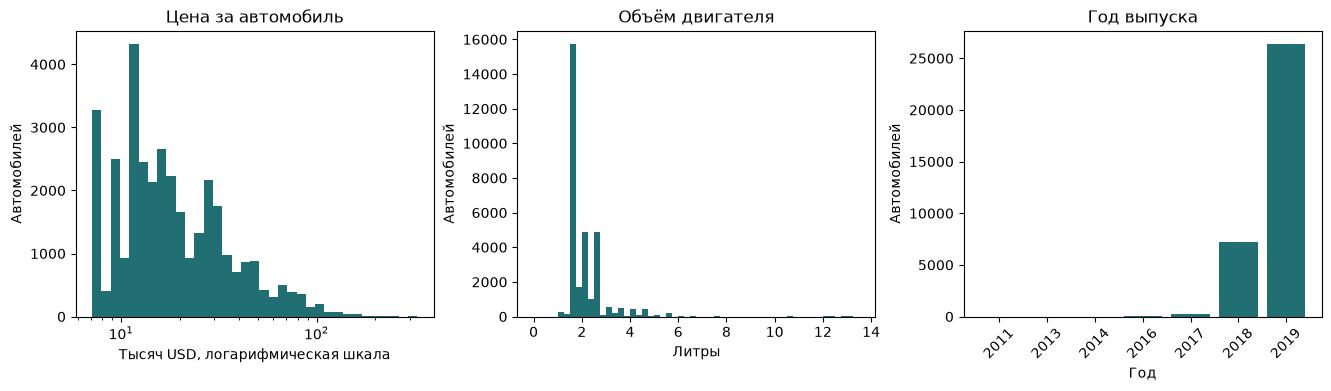

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.8), constrained_layout=True)
price = positive['unit_price_usd'].to_numpy() / 1_000
axes[0].hist(price, bins=np.geomspace(price.min(), price.max(), 36),
             weights=positive['units'].to_numpy(), color='#216e73')
axes[0].set_xscale('log')
axes[0].set(title='Цена за автомобиль', xlabel='Тысяч USD, логарифмическая шкала')

engines = positive.dropna(subset=['engine_l'])
axes[1].hist(engines['engine_l'], bins=np.arange(0, 13.6, .25),
             weights=engines['units'], color='#216e73')
axes[1].set(title='Объём двигателя', xlabel='Литры')

model_years = positive.groupby('model_year')['units'].sum()
axes[2].bar(model_years.index.astype(str), model_years, color='#216e73')
axes[2].tick_params(axis='x', rotation=45)
axes[2].set(title='Год выпуска', xlabel='Год')
for ax in axes:
    ax.set_ylabel('Автомобилей')
plt.show()

Половина проданных автомобилей стоит от 11 300 до 27 902 USD при медиане 16 000 USD. Длинный правый хвост включает дорогие премиальные модели и коммерческую технику. Расчёт взвешен по автомобилям, поэтому крупная партия влияет пропорционально её объёму. Наибольшая концентрация объёмов двигателя в районе 1,6–2,0 л. Присутствуют коммерческие машины с двигателями 10–13 л. Около 76% положительных продаж приходится на автомобили 2019 года выпуска, ещё примерно 21% — на 2018 год. Остальные годы и пропуски составляют небольшую часть.

### Объём двигателя и цена автомобиля

В анализ входят продажи на внутреннем рынке с известным объёмом двигателя. Каждой машине в партии соответствует одно наблюдение. Коэффициент Спирмена рассчитан как корреляция рангов объёма и цены за автомобиль. Дополнительно рассчитан коэффициент с одинаковым весом каждой строки выгрузки.

,Автомобилей,Ранговая корреляция Спирмена
Сегмент,,
Внутренний рынок,31400,0.73
Внедорожники,13014,0.77
Коммерческие автомобили,2440,0.26
Легковые автомобили,13808,0.78
Минивэны,1763,0.40
Пикапы,375,0.35


Известен объём двигателя у 31 400 из 34 726 автомобилей (90.42%).
Ранговая корреляция при одинаковом весе строк: 0.64.


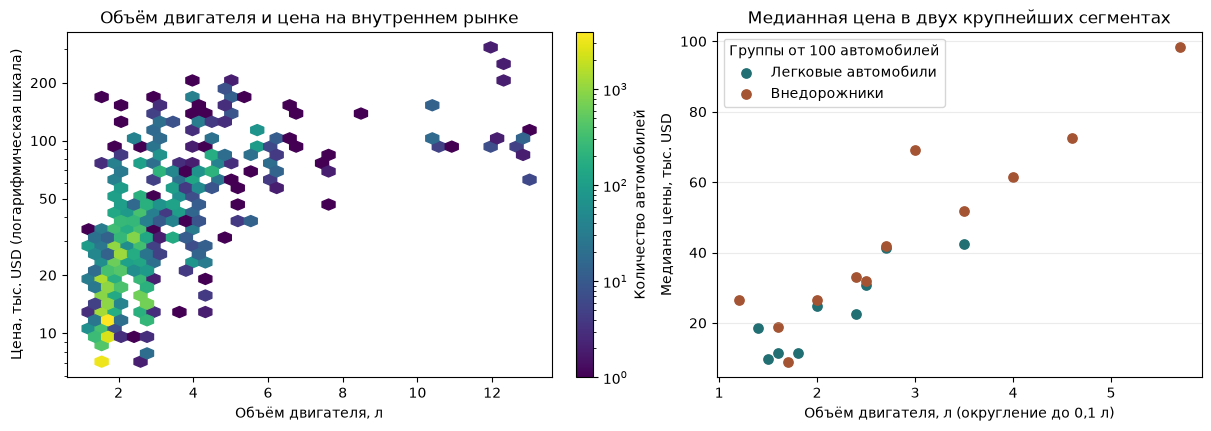

In [6]:
cars_with_engine = engines.loc[engines.index.repeat(engines['units'])]
market_segments = [('Внутренний рынок', cars_with_engine),
                   *cars_with_engine.groupby('segment_2013', observed=True)]

def engine_price_spearman(frame):
    return frame['engine_l'].rank().corr(frame['unit_price_usd'].rank())

engine_price = pd.DataFrame(
    [(label, len(frame), engine_price_spearman(frame)) for label, frame in market_segments],
    columns=['Сегмент', 'Автомобилей', 'Ранговая корреляция Спирмена'],
).set_index('Сегмент')
display(engine_price.round(2))
engine_coverage = 100 * len(cars_with_engine) / volume
print(f'Известен объём двигателя у {len(cars_with_engine):,} из {volume:,} автомобилей '
      f'({engine_coverage:.2f}%).'.replace(',', ' '))
print(f'Ранговая корреляция при одинаковом весе строк: {engine_price_spearman(engines):.2f}.')

fig, (density_ax, segment_ax) = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
density = density_ax.hexbin(
    cars_with_engine['engine_l'].to_numpy(),
    cars_with_engine['unit_price_usd'].to_numpy() / 1_000,
    gridsize=34, yscale='log', bins='log', mincnt=1, cmap='viridis',
)
density_ax.set(title='Объём двигателя и цена на внутреннем рынке',
               xlabel='Объём двигателя, л', ylabel='Цена, тыс. USD (логарифмическая шкала)')
price_ticks = [10, 20, 50, 100, 200]
density_ax.set_yticks(price_ticks, labels=[str(tick) for tick in price_ticks])
fig.colorbar(density, ax=density_ax, label='Количество автомобилей')

for segment, color in [('Легковые автомобили', '#216e73'), ('Внедорожники', '#a45433')]:
    segment_cars = cars_with_engine.loc[cars_with_engine['segment_2013'].eq(segment)]
    price_by_engine = segment_cars.groupby(segment_cars['engine_l'].round(1))['unit_price_usd'].agg(
        ['size', 'median']
    )
    common_sizes = price_by_engine.loc[price_by_engine['size'].ge(100)]
    segment_ax.scatter(common_sizes.index, common_sizes['median'] / 1_000,
                       s=45, color=color, label=segment)

segment_ax.set(title='Медианная цена в двух крупнейших сегментах',
               xlabel='Объём двигателя, л (округление до 0,1 л)', ylabel='Медиана цены, тыс. USD')
segment_ax.grid(axis='y', alpha=.25)
segment_ax.legend(title='Группы от 100 автомобилей')
plt.show()

Объём двигателя известен у 31 400 из 34 726 проданных автомобилей (90,42%). Коэффициент Спирмена составляет 0,73: большему объёму обычно соответствует более высокая цена. При одинаковом весе каждой строки коэффициент составляет 0,64.

Связь сохраняется внутри легкового сегмента (0,78) и среди внедорожников (0,77). У коммерческих автомобилей коэффициент ниже (0,26). Даже в пределах одного сегмента медианы по отдельным объёмам колеблются. Для оценки отдельного вклада объёма нужен анализ с учётом марки, модели, комплектации и года выпуска.

,Автомобилей нетто,"Оборот, USD"
Бренд,,
Lada,11085,1.077667e+08
Hyundai,4987,1.133128e+08
Toyota,3636,1.499261e+08
Kia,2346,4.541500e+07
Nissan,1651,3.972274e+07
GAZ,1361,2.382319e+07
UAZ,1217,1.690020e+07
Renault,1193,1.606602e+07
Volkswagen,1048,2.165401e+07


Автомобилей нетто  Оборот, USD
Бренд      Модель                                
Lada       Granta               3663  26664805.26
           Vesta                2650  31081473.68
           4x4                  2469  22338600.00
           Largus               1682  19161900.00
Hyundai    Tucson               1370  36314314.26
           Accent               1246  20837341.39
Toyota     Camry                1120  37396000.00
Hyundai    Creta                1054  21112880.07
Kia        Rio                   993  13755500.00
Volkswagen Polo                  791  12243684.30

,Автомобилей нетто,"Оборот, USD"
Регион,,
Алматы,7682,2.402482e+08
Нур-Султан,5682,1.541434e+08
Атырау,2503,4.787356e+07
Караганда,2355,4.523425e+07
Шымкент,2318,4.650918e+07
Костанай,2212,4.552470e+07
Усть-Каменогорск,1865,3.507892e+07
Уральск,1743,3.367877e+07
Актобе,1422,3.174821e+07


,Автомобилей нетто,"Оборот, USD"
Топливо,,
F,30817,6.788222e+08
<NA>,2985,6.979161e+07
D,903,5.118693e+07
HYB,14,1.096389e+06
E,6,8.006953e+05


,Автомобилей нетто,"Оборот, USD"
Коробка передач,,
Автомат,17862,5.313764e+08
Механика,13904,1.959342e+08
<NA>,2959,7.438723e+07


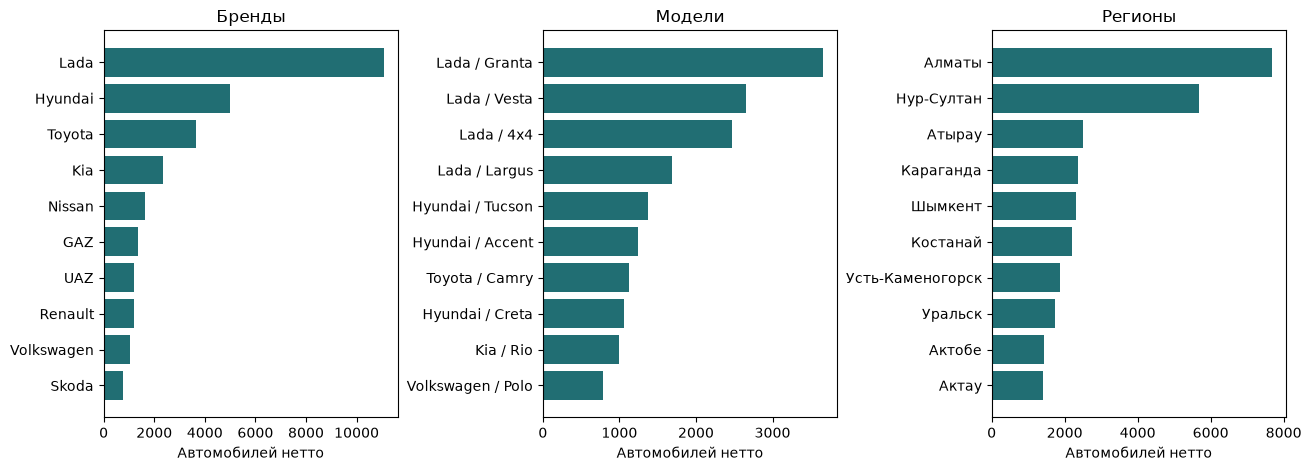

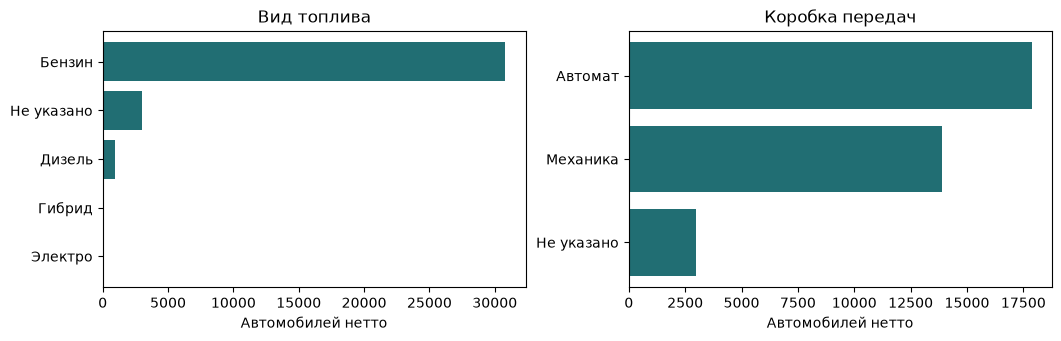

In [7]:
def show_market_group(group, label, limit=None):
    result = totals(market, group).sort_values('units', ascending=False)
    shown = result if limit is None else result.head(limit)
    view = shown.rename(columns={'units': 'Автомобилей нетто', 'turnover': 'Оборот, USD'})
    display(view.rename_axis(label).round(2))
    return shown

brands = show_market_group('brand', 'Бренд', 10)
models = show_market_group(['brand', 'model'], ['Бренд', 'Модель'], 10)
regions = show_market_group('region', 'Регион', 10)
fuels = show_market_group('fuel_type', 'Топливо')
transmissions = show_market_group('transmission', 'Коробка передач')

fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), constrained_layout=True)
labels = [
    (brands.index, brands['units'], 'Бренды'),
    ([' / '.join(idx) for idx in models.index], models['units'], 'Модели'),
    (regions.index, regions['units'], 'Регионы'),
]
for ax, (names, values, title) in zip(axes, labels):
    ax.barh(names, values.astype(int), color='#216e73')
    ax.invert_yaxis()
    ax.set(title=title, xlabel='Автомобилей нетто')
plt.show()

fuel_names = {'F': 'Бензин', 'D': 'Дизель', 'HYB': 'Гибрид', 'E': 'Электро'}
fuel_labels = [fuel_names.get(key, 'Не указано') for key in fuels.index]
transmission_labels = transmissions.index.astype('string').fillna('Не указано')
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.3), constrained_layout=True)
for ax, (name, values, title) in zip(axes, [
    (fuel_labels, fuels['units'], 'Вид топлива'),
    (transmission_labels, transmissions['units'], 'Коробка передач'),
]):
    ax.barh(name, values.astype(int), color='#216e73')
    ax.invert_yaxis()
    ax.set(title=title, xlabel='Автомобилей нетто')
plt.show()

В очищенной выборке по объёму лидируют Lada (11 085), Hyundai (4 987) и Toyota (3 636). Первые четыре модели принадлежат Lada, а крупнейшие регионы по числу автомобилей — Алматы и Нур-Султан. Порядок Hyundai и Toyota меняется, если сохранить исходные повторы. Из учтённых автомобилей 30 817 бензиновых (88,75% всего объёма, включая неизвестный вид топлива) и шесть электрических. Для 8,60% единиц вид топлива не указан, поэтому небольшие группы гибридов и электромобилей стоит интерпретировать с оглядкой на неполноту характеристик. Зарегистрировано 17 862 автомобиля с автоматической коробкой и 13 904 с механической. Ещё у 2 959 тип неизвестен.

,"Весь рынок, авто","Меркур Авто, авто","Доля, %"
sale_date,,,
2019-01-31,2953,58,1.96
2019-02-28,3193,93,2.91
2019-03-31,3437,62,1.8
2019-04-30,4282,68,1.59
2019-05-31,4257,66,1.55
2019-06-30,4177,8,0.19
2019-07-31,4432,16,0.36
2019-08-31,4250,13,0.31
2019-09-30,3744,10,0.27


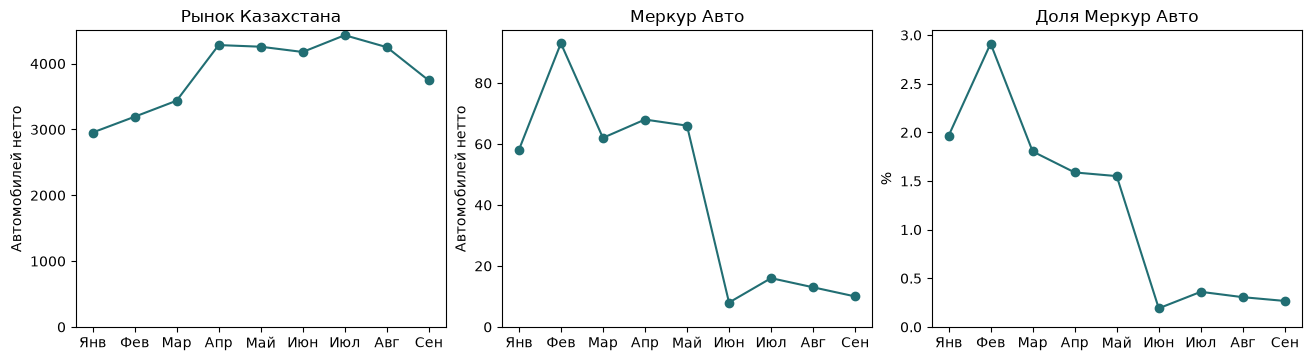

In [8]:
def compare_groups(group):
    results = totals(market, group).join(totals(mercur, group).add_suffix('_mercur'))
    results['units_mercur'] = results['units_mercur'].fillna(0).astype('Int64')
    results['turnover_mercur'] = results['turnover_mercur'].fillna(0)
    results['unit_share'] = 100 * results['units_mercur'] / results['units']
    results['turnover_share'] = 100 * results['turnover_mercur'] / results['turnover']
    results['mercur_mix'] = 100 * results['units_mercur'] / mercur['quantity'].sum()
    results['market_mix'] = 100 * results['units'] / market['quantity'].sum()
    return results

monthly = compare_groups('sale_date')
display(monthly[['units', 'units_mercur', 'unit_share']].rename(columns={
    'units': 'Весь рынок, авто', 'units_mercur': 'Меркур Авто, авто', 'unit_share': 'Доля, %',
}).round(2))

months = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн', 'Июл', 'Авг', 'Сен']
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), constrained_layout=True)
for ax, (values, title, units) in zip(axes, [
    (monthly['units'], 'Рынок Казахстана', 'Автомобилей нетто'),
    (monthly['units_mercur'], 'Меркур Авто', 'Автомобилей нетто'),
    (monthly['unit_share'], 'Доля Меркур Авто', '%'),
]):
    ax.plot(months, values.astype(float), 'o-', color='#216e73')
    ax.set(title=title, ylabel=units, ylim=(0, None))
plt.show()

Рынок в очищенных данных вырос с 2 953 автомобилей в январе до 4 432 в июле. В первом квартале «Меркур Авто» продал 213 автомобилей, в третьем — 39, хотя рынок вырос с 9 583 до 12 426. Спад начинается в июне и сохраняется в сценарии со всеми строками. Девяти месяцев одного года недостаточно для выводов о сезонности или причинах спада.

## 3. Доля рынка, структура продаж и средний чек

In [9]:
market_units = market['quantity'].sum()
market_turnover = market['sales_usd'].sum()
mercur_units = mercur['quantity'].sum()
mercur_turnover = mercur['sales_usd'].sum()
kpi = pd.DataFrame({
    'Рынок Казахстана': [
        market_units, market_turnover, market_turnover / market_units, 100, 100,
    ],
    'Меркур Авто': [
        mercur_units, mercur_turnover, mercur_turnover / mercur_units,
        100 * mercur_units / market_units, 100 * mercur_turnover / market_turnover,
    ],
}, index=['Автомобилей нетто', 'Оборот, USD', 'Оборот на автомобиль, USD',
          'Доля в объёме, %', 'Доля в обороте, %'])
display(kpi.round(2))

company_totals = totals(market, 'company')
rank_units = int(company_totals['units'].rank(ascending=False, method='min').loc[MERCUR])
rank_turnover = int(company_totals['turnover'].rank(ascending=False, method='min').loc[MERCUR])
print(f'Место среди {len(company_totals)} компаний: {rank_units} по объёму, '
      f'{rank_turnover} по обороту.')

,Рынок Казахстана,Меркур Авто
Автомобилей нетто,3.472500e+04,394.00
"Оборот, USD",8.016979e+08,15121529.04
"Оборот на автомобиль, USD",2.308705e+04,38379.52
"Доля в объёме, %",1.000000e+02,1.13
"Доля в обороте, %",1.000000e+02,1.89


Место среди 33 компаний: 11 по объёму, 10 по обороту.


Под средним чеком здесь понимаем оборот нетто на проданный автомобиль. Архив допускает несколько автомобилей в строке и не содержит идентификатора заказа, поэтому средний чек на заказ вычислить невозможно. Оборот на автомобиль у дилера около 38,38 тыс. USD, по внутреннему рынку — 23,09 тыс. USD. Сравнение зависит от состава моделей. Audi и Porsche повышают средний оборот на автомобиль. Для сопоставимого ориентира ниже сравним Volkswagen у дилера и у остальных компаний с продажами этой марки.

In [10]:
table_columns = {
    'units': 'Рынок, авто', 'units_mercur': 'Меркур Авто, авто',
    'turnover_mercur': 'Оборот дилера, USD', 'unit_share': 'Доля рынка, % авто',
    'turnover_share': 'Доля рынка, % USD', 'mercur_mix': 'Структура дилера, % авто',
    'market_mix': 'Структура рынка, % авто',
}
brand_shares = compare_groups('brand')
mercur_brands = brand_shares.loc[brand_shares['units_mercur'].gt(0)].sort_values(
    'units_mercur', ascending=False,
)
regional_shares = compare_groups('region').sort_values('units', ascending=False)
segment_shares = compare_groups('segment_2013').sort_values('units', ascending=False)
class_shares = compare_groups('class_2013')
class_shares = class_shares.loc[class_shares['units_mercur'].gt(0)].sort_values(
    'units_mercur', ascending=False,
)

for label, table in [
    ('Марки Меркур Авто', mercur_brands), ('Регион', regional_shares),
    ('Сегмент', segment_shares), ('Класс с продажами дилера', class_shares),
]:
    display(table[list(table_columns)].rename(columns=table_columns).rename_axis(label).round(2))
for column, label in [('fuel_type', 'Топливо'), ('transmission', 'Коробка передач')]:
    mix = compare_groups(column)[['units', 'units_mercur', 'market_mix', 'mercur_mix']]
    mix.index = mix.index.astype('string').fillna('Не указано')
    display(mix.rename(columns=table_columns).rename_axis(label).round(2))
display(totals(mercur, ['brand', 'model']).sort_values('units', ascending=False).head(10))

comparable = market.loc[market['brand'].eq('Volkswagen')].assign(
    seller=lambda frame: frame['company'].eq(MERCUR).map(
        {True: 'Меркур Авто', False: 'Остальные компании'}
    )
)
volkswagen = totals(comparable, 'seller')
volkswagen['avg_price'] = volkswagen['turnover'] / volkswagen['units']
display(volkswagen.rename(columns={'units': 'Автомобилей', 'turnover': 'Оборот, USD',
                                  'avg_price': 'Оборот на автомобиль, USD'}).round(2))

,"Рынок, авто","Меркур Авто, авто","Оборот дилера, USD","Доля рынка, % авто","Доля рынка, % USD","Структура дилера, % авто","Структура рынка, % авто"
Марки Меркур Авто,,,,,,,
Volkswagen,1048,294,6299195.92,28.05,29.09,74.62,3.02
Porsche,52,52,5113512.70,100.0,100.00,13.2,0.15
Audi,48,48,3708820.43,100.0,100.00,12.18,0.14


,"Рынок, авто","Меркур Авто, авто","Оборот дилера, USD","Доля рынка, % авто","Доля рынка, % USD","Структура дилера, % авто","Структура рынка, % авто"
Регион,,,,,,,
Алматы,7682,251,11600584.29,3.27,4.83,63.71,22.12
Нур-Султан,5682,51,1502141.15,0.9,0.97,12.94,16.36
Атырау,2503,43,790024.51,1.72,1.65,10.91,7.21
Караганда,2355,21,399332.52,0.89,0.88,5.33,6.78
Шымкент,2318,0,0.00,0.0,0.00,0.0,6.68
Костанай,2212,14,538794.64,0.63,1.18,3.55,6.37
Усть-Каменогорск,1865,0,0.00,0.0,0.00,0.0,5.37
Уральск,1743,14,290651.93,0.8,0.86,3.55,5.02
Актобе,1422,0,0.00,0.0,0.00,0.0,4.1


,"Рынок, авто","Меркур Авто, авто","Оборот дилера, USD","Доля рынка, % авто","Доля рынка, % USD","Структура дилера, % авто","Структура рынка, % авто"
Сегмент,,,,,,,
Легковые автомобили,15008,234,5809570.89,1.56,2.45,59.39,43.22
Внедорожники,14047,145,8703315.10,1.03,2.07,36.8,40.45
Коммерческие автомобили,3487,8,251411.12,0.23,0.23,2.03,10.04
Минивэны,1798,5,284190.40,0.28,1.28,1.27,5.18
Пикапы,385,2,73041.55,0.52,0.64,0.51,1.11


,"Рынок, авто","Меркур Авто, авто","Оборот дилера, USD","Доля рынка, % авто","Доля рынка, % USD","Структура дилера, % авто","Структура рынка, % авто"
Класс с продажами дилера,,,,,,,
B класс,11046,202,2993377.30,1.83,2.38,51.27,31.81
Компактные SUV,4389,67,2184873.71,1.53,1.81,17.01,12.64
Полноразмерные SUV,1999,67,5842651.69,3.35,4.70,17.01,5.76
F класс,45,13,1636860.80,28.89,34.92,3.3,0.13
Среднеразмерные SUV,2800,11,675789.70,0.39,0.59,2.79,8.06
E класс,201,9,699852.51,4.48,7.42,2.28,0.58
Микроавтобусы,396,8,251411.12,2.02,3.21,2.03,1.14
C класс,1926,5,113796.19,0.26,0.28,1.27,5.55
Полноразмерный Минивэн,44,5,284190.40,11.36,14.44,1.27,0.13


,"Рынок, авто","Меркур Авто, авто","Структура рынка, % авто","Структура дилера, % авто"
Топливо,,,,
D,903,1,2.6,0.25
E,6,0,0.02,0.0
F,30817,389,88.75,98.73
HYB,14,4,0.04,1.02
Не указано,2985,0,8.6,0.0


,"Рынок, авто","Меркур Авто, авто","Структура рынка, % авто","Структура дилера, % авто"
Коробка передач,,,,
Автомат,17862,341,51.44,86.55
Механика,13904,52,40.04,13.2
Не указано,2959,1,8.52,0.25


units      turnover
brand      model                                  
Volkswagen Polo                  202  2.993377e+06
           Tiguan                 67  2.184874e+06
Porsche    Cayenne                28  2.856255e+06
Audi       Q8                     17  1.521388e+06
Porsche    Macan                  15  1.015620e+06
Audi       Q5                      8  4.332374e+05
Porsche    Panamera                8  1.079062e+06
Volkswagen Transporter Kasten      7  2.148903e+05
Audi       A6                      7  5.287525e+05
           A8                      5  5.577992e+05

,Автомобилей,"Оборот, USD","Оборот на автомобиль, USD"
seller,,,
Меркур Авто,294,6299195.92,21425.84
Остальные компании,754,15354814.26,20364.48


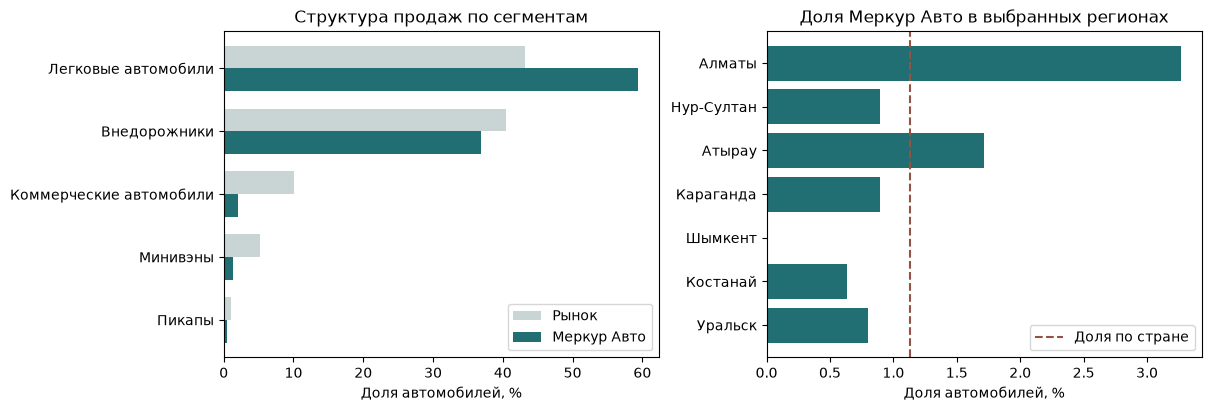

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
segment_positions = np.arange(len(segment_shares))
axes[0].barh(segment_positions - .18, segment_shares['market_mix'].astype(float),
             height=.36, color='#c9d5d5', label='Рынок')
axes[0].barh(segment_positions + .18, segment_shares['mercur_mix'].astype(float),
             height=.36, color='#216e73', label='Меркур Авто')
axes[0].set_yticks(segment_positions, segment_shares.index)
axes[0].set(title='Структура продаж по сегментам', xlabel='Доля автомобилей, %')
axes[0].invert_yaxis()
axes[0].legend()

visible_regions = regional_shares.loc[
    regional_shares['units_mercur'].gt(0) | regional_shares.index.isin(['Шымкент'])
]
axes[1].barh(visible_regions.index, visible_regions['unit_share'].astype(float),
             color='#216e73')
axes[1].axvline(100 * mercur_units / market_units, linestyle='--',
               color='#925343', label='Доля по стране')
axes[1].set(title='Доля Меркур Авто в выбранных регионах', xlabel='Доля автомобилей, %')
axes[1].invert_yaxis()
axes[1].legend()
plt.show()

- Volkswagen даёт 294 из 394 автомобилей дилера (74,6%). Внутри рынка Volkswagen доля дилера — 28,05%. Средний оборот на Volkswagen составил 21,43 тыс. USD против 20,36 тыс. USD у других продавцов марки. Остаются различия в моделях и комплектациях.
- Porsche и Audi вместе дали 100 автомобилей и 8,82 млн USD, то есть 25,4% количества и 58,3% оборота дилера. В этой выгрузке все продажи этих двух марок относятся к его компании. Присутствие независимых продавцов за рамками источника из этого расчёта определить нельзя.
- Алматы даёт 251 автомобиль (63,7% продаж компании) и 76,7% оборота. Здесь доля по количеству 3,27%, в Нур-Султане — 0,90%, в Атырау — 1,72%. В Шымкенте объём рынка 2 318 автомобилей, при этом строк дилера нет. Для проверки потенциала нужны данные по маркам, партнёрам и покрытию поставок.
- Легковые автомобили составляют 59,4% объёма дилера против 43,2% по рынку. Внедорожников 145, на них приходится 8,70 млн USD, или 57,6% оборота дилера. В классе полноразмерных внедорожников доля по количеству 3,35%, по обороту 4,70%. Коммерческий сегмент составляет лишь восемь автомобилей дилера на 3 487 по рынку.
- В «Меркур Авто» автоматическая коробка указана у 86,5% автомобилей, в целом по рынку — у 51,4%. Для бензина доли составляют 98,7% и 88,7%. В знаменателях оставлены записи с неизвестным типом топлива или трансмиссии.

## 4. Проверка чувствительности к правилу удаления повторов

In [12]:
with_repeats, _ = clean_sales(raw, drop_exact=False)
full_market = with_repeats.loc[with_repeats['region'].ne('Экспорт')]

def sensitivity_metrics(frame):
    target = frame.loc[frame['company'].eq(MERCUR)]
    market_sales = frame['sales_usd'].sum()
    target_sales = target['sales_usd'].sum()
    market_count = frame['quantity'].sum()
    target_count = target['quantity'].sum()
    return {
        'Рынок, авто': market_count,
        'Дилер, авто': target_count,
        'Доля по количеству, %': 100 * target_count / market_count,
        'Доля по обороту, %': 100 * target_sales / market_sales,
        'Рынок, USD на авто': market_sales / market_count,
        'Дилер, USD на авто': target_sales / target_count,
        'Дилер, I квартал, авто': target.loc[target['sale_date'].dt.quarter.eq(1), 'quantity'].sum(),
        'Дилер, III квартал, авто': target.loc[target['sale_date'].dt.quarter.eq(3), 'quantity'].sum(),
    }

scenarios = pd.DataFrame({
    'Точные повторы удалены': sensitivity_metrics(market),
    'Сохранены все исходные строки': sensitivity_metrics(full_market),
})
display(scenarios.round(2))
display(totals(full_market, 'brand').sort_values('units', ascending=False).head(5))

,Точные повторы удалены,Сохранены все исходные строки
"Рынок, авто",34725.00,51955.00
"Дилер, авто",394.00,650.00
"Доля по количеству, %",1.13,1.25
"Доля по обороту, %",1.89,1.48
"Рынок, USD на авто",23087.05,25238.70
"Дилер, USD на авто",38379.52,29777.35
"Дилер, I квартал, авто",213.00,369.00
"Дилер, III квартал, авто",39.00,41.00


,units,turnover
brand,,
Lada,11092,1.078475e+08
Toyota,10524,3.927176e+08
Hyundai,10008,2.261316e+08
Kia,2358,4.566970e+07
GAZ,1821,3.228620e+07


В обоих сценариях доля «Меркур Авто» по количеству около 1,1–1,3%, оборот на автомобиль выше среднего, а объём в III квартале ниже I. Размер премии к среднему рынку чувствителен к очистке: около 66% в очищенной выборке и около 18% при исходной кратности. До управленческих решений по абсолютным объёмам следует сверить выгрузку с идентификаторами операций и итогами учёта по месяцам.

В первую очередь стоит разобрать спад с июня по компании, модели и городу, сверив поставки и полноту данных. Для развития в Нур-Султане и Шымкенте полезно измерить объём сопоставимых классов и конкурентное присутствие. Сравнивать экономику расширения следует по марже, сопоставимой модельной линейке и затратам на покрытие региона.